# 🩺 Fine-tuning CLIP for Skin-Lesion Classification (HAM10000)
**CP461 Final Project · extension: fine-tuned CLIP + physician-in-the-loop web app**

The original project reported two CLIP baselines on a lesion-level held-out test set:

| Baseline | What it is | Accuracy reported |
|---|---|---|
| **B1 Zero-shot CLIP** ("Original CLIP") | text prompts only, no training | ≈ 25 % |
| **B2 Linear probe** ("Improved CLIP") | frozen image features + logistic regression | ≈ 55 % |

This notebook adds **M-FT: a fine-tuned CLIP** and compares it with both baselines **on exactly the same test images**.

**Recipe (LP-FT, Kumar et al. 2022 + partial fine-tuning)**
1. Cosine classification head initialised from CLIP text embeddings of the class names.
2. *Stage 1 – linear probe:* train only the head on frozen features (avoids distorting good features with a random head).
3. *Stage 2 – partial fine-tuning:* unfreeze the **last 4 ViT blocks + `ln_post` + `proj`** with a small learning rate, class-balanced sampling, label smoothing, augmentation (flips / rotation / crop / mild colour jitter), AMP, cosine schedule, early stopping on a *lesion-grouped* validation split.
4. Temperature scaling on the validation split (calibrated confidence for the web app).
5. Paired bootstrap (resampling whole lesions) to check the improvement is not noise.
6. Export `clip_skin_ft.pt`, `metadata.json` and a small replay set for the web app and the feedback-retraining loop.

**Run it on a GPU** (Colab: *Runtime → Change runtime type → T4 GPU*; Kaggle: add the HAM10000 dataset + GPU). ~15–25 min on a T4.
> ⚠️ Research / education only. Not a medical device.

## 1 · Setup

In [1]:
!pip install -q ftfy regex tqdm scikit-learn seaborn matplotlib kagglehub
!pip install -q git+https://github.com/openai/CLIP.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, glob, math, json, time, random, shutil, warnings
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
from torchvision import transforms as T
import clip
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

# ---------------- configuration ----------------
SEED          = 42
BACKBONE      = "ViT-B/32"     # "ViT-B/16" is usually a few points better but ~4x slower
# --- test set: IDENTICAL protocol to the original project (<=500 img/class sample, group split by lesion_id)
MAX_PER_CLASS = 500
N_SPLITS      = 4
# --- training pool: every remaining HAM10000 image whose lesion is NOT in the test set
TRAIN_CAP_PER_CLASS = 1500     # caps the dominant 'nv' class
VAL_SPLITS    = 8              # 1/8 of the training pool (grouped by lesion) -> validation
# --- fine-tuning
N_UNFROZEN    = 4              # last N transformer blocks tuned (0 = head only)
EPOCHS        = 12
PATIENCE      = 3
BATCH_SIZE    = 64
LR_BACKBONE   = 1e-5
LR_HEAD       = 1e-3
WEIGHT_DECAY  = 0.05
LABEL_SMOOTH  = 0.1
MODEL_VERSION = "ft-v1"
OUT_DIR       = "skin_clip_export"

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
if device == "cpu":
    print("⚠️ No GPU found: fine-tuning will be very slow. Switch the runtime to a GPU.")
os.makedirs(OUT_DIR, exist_ok=True)

device: cuda


## 2 · Data: same test set as the baselines, larger training pool

In [3]:
import kagglehub

def locate_dataset():
    local = "/kaggle/input/skin-cancer-mnist-ham10000"
    if os.path.exists(os.path.join(local, "HAM10000_metadata.csv")):
        return local
    return kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")

dataset_path = locate_dataset()
image_path_dict = {os.path.splitext(os.path.basename(p))[0]: p
                   for p in glob.glob(os.path.join(dataset_path, "**", "*.jpg"), recursive=True)}
df = pd.read_csv(os.path.join(dataset_path, "HAM10000_metadata.csv"))

dx_mapping = {"nv": "melanocytic nevus", "mel": "melanoma", "bkl": "benign keratosis",
              "bcc": "basal cell carcinoma", "akiec": "actinic keratosis",
              "vasc": "vascular lesion", "df": "dermatofibroma"}
CODES   = list(dx_mapping.keys())
classes = list(dx_mapping.values())
K, MEL  = len(classes), classes.index("melanoma")
class_to_idx = {c: i for i, c in enumerate(classes)}

df["class_name"] = df["dx"].map(dx_mapping)
df["img_path"]   = df["image_id"].map(image_path_dict)
df_valid = df.dropna(subset=["img_path"]).copy()
df_valid["y"] = df_valid["class_name"].map(class_to_idx)
print(f"{len(df_valid):,} images, {df_valid['lesion_id'].nunique():,} lesions")

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
10,015 images, 7,470 lesions


In [4]:
from sklearn.model_selection import StratifiedGroupKFold

# ---- 2a. TEST SET: reproduces the original notebook exactly (same sampling + split + seed)
parts = [g.sample(min(len(g), MAX_PER_CLASS), random_state=SEED) for _, g in df_valid.groupby("class_name")]
sample_df = pd.concat(parts).sample(frac=1, random_state=SEED).reset_index(drop=True)
y_s, groups_s = sample_df["class_name"].map(class_to_idx).values, sample_df["lesion_id"].values
sgkf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
_, test_idx = next(sgkf.split(np.zeros(len(sample_df)), y_s, groups_s))
test_df = sample_df.iloc[test_idx].reset_index(drop=True)
test_lesions = set(test_df["lesion_id"])

# ---- 2b. TRAINING POOL: all other images whose lesion never appears in the test set
pool = df_valid[~df_valid["lesion_id"].isin(test_lesions)]
pool = pd.concat([g.sample(min(len(g), TRAIN_CAP_PER_CLASS), random_state=SEED) for _, g in pool.groupby("class_name")])
pool = pool.sample(frac=1, random_state=SEED).reset_index(drop=True)

# ---- 2c. validation = grouped slice of the pool (early stopping, temperature scaling, C selection)
tr_i, va_i = next(StratifiedGroupKFold(n_splits=VAL_SPLITS, shuffle=True, random_state=SEED)
                  .split(np.zeros(len(pool)), pool["y"].values, pool["lesion_id"].values))
train_df, val_df = pool.iloc[tr_i].reset_index(drop=True), pool.iloc[va_i].reset_index(drop=True)

assert not (set(train_df["lesion_id"]) & test_lesions) and not (set(val_df["lesion_id"]) & test_lesions)
assert not (set(train_df["lesion_id"]) & set(val_df["lesion_id"]))
print("✅ no lesion overlap between train / val / test")
pd.DataFrame({"train": train_df["class_name"].value_counts(), "val": val_df["class_name"].value_counts(),
              "test": test_df["class_name"].value_counts()}).reindex(classes)

✅ no lesion overlap between train / val / test


,train,val,test
class_name,,,
melanocytic nevus,1325,175,123
melanoma,818,116,125
benign keratosis,792,119,130
basal cell carcinoma,354,40,118
actinic keratosis,214,26,87
vascular lesion,76,25,41
dermatofibroma,74,12,29


## 3 · Load CLIP and images

In [5]:
base, preprocess = clip.load(BACKBONE, device="cpu", jit=False)
base = base.float().eval()          # fp32 on CPU first: clip.load keeps fp16 weights on GPU, unsuitable for fine-tuning
print("loaded CLIP", BACKBONE, "| visual params: %.1fM" % (sum(p.numel() for p in base.visual.parameters()) / 1e6))

def load_short224(path):
    # == CLIP's Resize(224, bicubic) applied once, kept in RAM; CenterCrop(224) happens in `preprocess` / aug
    im = Image.open(path).convert("RGB")
    w, h = im.size
    s = 224 / min(w, h)
    return im.resize((max(224, int(round(w * s))), max(224, int(round(h * s)))), Image.BICUBIC)

def load_all(paths):
    with ThreadPoolExecutor(8) as ex:
        return list(tqdm(ex.map(load_short224, paths), total=len(paths), leave=False))

t0 = time.time()
imgs_train, imgs_val, imgs_test = (load_all(d["img_path"].tolist()) for d in (train_df, val_df, test_df))
y_train, y_val, y_test = train_df["y"].values, val_df["y"].values, test_df["y"].values
print(f"cached {len(imgs_train)+len(imgs_val)+len(imgs_test):,} images in {time.time()-t0:.0f}s")

100%|████████████████████████████████████████| 338M/338M [00:02<00:00, 171MiB/s]


loaded CLIP ViT-B/32 | visual params: 87.8M


  0%|          | 0/3653 [00:00<?, ?it/s]

  0%|          | 0/513 [00:00<?, ?it/s]

  0%|          | 0/653 [00:00<?, ?it/s]

cached 4,819 images in 42s


In [6]:
MEAN, STD = (0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711)
train_tf = T.Compose([
    T.RandomResizedCrop(224, scale=(0.6, 1.0), interpolation=T.InterpolationMode.BICUBIC),
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(), T.RandomRotation(180),
    T.ColorJitter(0.15, 0.15, 0.1, 0.02), T.ToTensor(), T.Normalize(MEAN, STD)])

class ListDS(torch.utils.data.Dataset):
    def __init__(self, imgs, y, tf): self.imgs, self.y, self.tf = imgs, y, tf
    def __len__(self): return len(self.imgs)
    def __getitem__(self, i): return self.tf(self.imgs[i]), int(self.y[i])

def loader(imgs, y, tf, shuffle=False, sampler=None, bs=BATCH_SIZE):
    return torch.utils.data.DataLoader(ListDS(imgs, y, tf), batch_size=bs, shuffle=shuffle and sampler is None,
                                       sampler=sampler, num_workers=2, drop_last=bool(sampler), pin_memory=True)

## 4 · Model definition
`SkinCLIPNet` is identical to the class in the web app's `core.py` (so the exported checkpoint loads there unchanged).

In [7]:
class SkinCLIPNet(nn.Module):
    """CLIP visual tower + cosine classifier head (init from text embeddings)."""
    def __init__(self, visual, head_weight, logit_scale=math.log(100.0)):
        super().__init__()
        self.visual = visual
        self.head = nn.Parameter(head_weight.detach().clone().float())
        self.logit_scale = nn.Parameter(torch.tensor(float(logit_scale)))
    def features(self, x): return F.normalize(self.visual(x).float(), dim=-1)
    def logits_from_features(self, f):
        return self.logit_scale.clamp(max=math.log(100.0)).exp() * f @ F.normalize(self.head, dim=-1).T
    def forward(self, x): return self.logits_from_features(self.features(x))
    def set_trainable(self, n_blocks):
        for p in self.visual.parameters(): p.requires_grad = False
        if n_blocks > 0:
            for blk in self.visual.transformer.resblocks[-n_blocks:]:
                for p in blk.parameters(): p.requires_grad = True
            self.visual.ln_post.requires_grad_(True); self.visual.proj.requires_grad_(True)
        return [n for n, p in self.visual.named_parameters() if p.requires_grad]
    def tuned_visual_state(self, n_blocks):
        names = set(self.set_trainable(n_blocks)) if n_blocks > 0 else set()
        return {k: v.detach().cpu().half() for k, v in self.visual.state_dict().items() if k in names}

ZS_PROMPT = "a clinical dermatological photo of {}"       # same prompt as the original baseline
@torch.no_grad()
def text_head(prompts_per_class):
    out = []
    for prompts in prompts_per_class:
        t = F.normalize(base.encode_text(clip.tokenize(prompts)).float(), dim=-1).mean(0)
        out.append(t / t.norm())
    return torch.stack(out)

W_zs = text_head([[ZS_PROMPT.format(c)] for c in classes])           # B1 (original baseline prompt)
net = SkinCLIPNet(base.visual, W_zs).to(device).eval()

## 5 · Baselines on the frozen CLIP (same test images)

In [8]:
@torch.no_grad()
def extract(net, imgs, tf, bs=128):
    net.eval(); out = []
    dl = torch.utils.data.DataLoader(ListDS(imgs, np.zeros(len(imgs), int), tf), batch_size=bs, num_workers=2)
    for x, _ in dl:
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=device == "cuda"):
            out.append(net.features(x.to(device)).float().cpu())
    return torch.cat(out)

F_train, F_val, F_test = (extract(net, im, preprocess) for im in (imgs_train, imgs_val, imgs_test))   # frozen features
def softmax_np(z): z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

results = {}
# B1: zero-shot, original prompt (== the project's "Original CLIP")
p = softmax_np(100 * (F_test @ W_zs.cpu().T).numpy())
results["B1 Zero-shot CLIP (baseline)"] = {"prob": p, "pred": p.argmax(1)}

# B1b: zero-shot with a prompt ensemble (a stronger, fairer zero-shot baseline)
TEMPLATES = ["a dermoscopy image of {}", "a close-up dermoscopic photo of a skin lesion: {}", "a clinical dermatological photo of {}"]
W_ens = text_head([[t.format(c) for t in TEMPLATES] for c in classes])
p = softmax_np(100 * (F_test @ W_ens.cpu().T).numpy())
results["B1b Zero-shot CLIP (prompt ensemble)"] = {"prob": p, "pred": p.argmax(1)}

# B2: linear probe on frozen features, trained on the SAME enlarged pool (fair comparison)
from sklearn.linear_model import LogisticRegression
best = (-1, None)
for Cval in [0.3, 1, 3, 10, 30, 100]:
    lr_ = LogisticRegression(C=Cval, max_iter=5000, class_weight="balanced").fit(F_train.numpy(), y_train)
    bal = np.mean([(lr_.predict(F_val.numpy())[y_val == k] == k).mean() for k in range(K)])
    if bal > best[0]: best = (bal, lr_, Cval)
print(f"linear probe: best C={best[2]} (val balanced acc {best[0]:.3f})")
lp = best[1]
results["B2 Linear probe (frozen CLIP)"] = {"prob": lp.predict_proba(F_test.numpy()), "pred": lp.predict(F_test.numpy())}
for n_, r in results.items(): print(f"{n_:<42} test acc = {(r['pred'] == y_test).mean():.4f}")

linear probe: best C=3 (val balanced acc 0.702)
B1 Zero-shot CLIP (baseline)               test acc = 0.2603
B1b Zero-shot CLIP (prompt ensemble)       test acc = 0.2282
B2 Linear probe (frozen CLIP)              test acc = 0.6462


## 6 · Fine-tuning (LP-FT)
**Stage 1** trains only the cosine head on the cached frozen features.  
**Stage 2** unfreezes the last blocks and fine-tunes end-to-end with augmentation.

In [9]:
# ---------- Stage 1: head-only on frozen features ----------
head = nn.Parameter(W_zs.clone().float().to(device))
scale = nn.Parameter(torch.tensor(math.log(30.0), device=device))
Xtr, Ytr = F_train.to(device), torch.as_tensor(y_train).to(device)
cw = torch.as_tensor(len(y_train) / (K * np.bincount(y_train, minlength=K)), dtype=torch.float32, device=device)
opt = torch.optim.AdamW([head, scale], lr=3e-3, weight_decay=1e-4)
for step in range(600):
    logits = scale.exp().clamp(max=100) * Xtr @ F.normalize(head, dim=-1).T
    loss = F.cross_entropy(logits, Ytr, weight=cw, label_smoothing=LABEL_SMOOTH)
    opt.zero_grad(); loss.backward(); opt.step()
with torch.no_grad():
    net.head.copy_(head.detach()); net.logit_scale.copy_(scale.detach().clamp(max=math.log(100)))
    acc1 = ((net.logits_from_features(F_val.to(device)).argmax(1).cpu().numpy()) == y_val).mean()
print(f"stage 1 done · loss {loss.item():.3f} · val acc {acc1:.3f}")

stage 1 done · loss 1.264 · val acc 0.577


fine-tuning 51 visual tensors · 28.7M trainable params
epoch  1/12 loss 1.315 | val acc 0.554 macro-F1 0.533 | 29s  ← best
epoch  2/12 loss 1.041 | val acc 0.600 macro-F1 0.599 | 29s  ← best
epoch  3/12 loss 0.915 | val acc 0.678 macro-F1 0.614 | 29s  ← best
epoch  4/12 loss 0.860 | val acc 0.676 macro-F1 0.652 | 29s  ← best
epoch  5/12 loss 0.842 | val acc 0.688 macro-F1 0.650 | 30s
epoch  6/12 loss 0.791 | val acc 0.712 macro-F1 0.642 | 29s
epoch  7/12 loss 0.764 | val acc 0.676 macro-F1 0.634 | 29s
early stopping


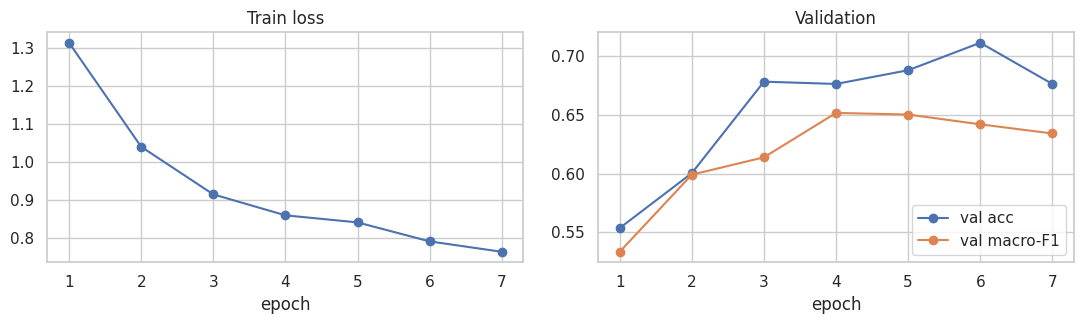

In [10]:
# ---------- Stage 2: partial fine-tuning ----------
from sklearn.metrics import f1_score, accuracy_score
trainable_names = net.set_trainable(N_UNFROZEN)
n_tr = sum(p.numel() for p in net.parameters() if p.requires_grad)
print(f"fine-tuning {len(trainable_names)} visual tensors · {n_tr/1e6:.1f}M trainable params")

bb_params = [p for p in net.visual.parameters() if p.requires_grad]
opt = torch.optim.AdamW([{"params": bb_params, "lr": LR_BACKBONE},
                         {"params": [net.head, net.logit_scale], "lr": LR_HEAD}], weight_decay=WEIGHT_DECAY)
counts = np.bincount(y_train, minlength=K)
sampler = torch.utils.data.WeightedRandomSampler(torch.as_tensor(1.0 / counts[y_train], dtype=torch.double),
                                                 num_samples=len(y_train), replacement=True)
train_dl = loader(imgs_train, y_train, train_tf, sampler=sampler)
total_steps = EPOCHS * len(train_dl); warm = max(1, int(0.08 * total_steps))
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm
                                          else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total_steps - warm))))
scaler = torch.cuda.amp.GradScaler(enabled=device == "cuda")

@torch.no_grad()
def eval_logits(imgs, tta=False, bs=128):
    net.eval(); outs = []
    dl = torch.utils.data.DataLoader(ListDS(imgs, np.zeros(len(imgs), int), preprocess), batch_size=bs, num_workers=2)
    for x, _ in dl:
        x = x.to(device)
        views = [x] + ([x.flip(-1), x.flip(-2)] if tta else [])
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=device == "cuda"):
            outs.append(torch.stack([net(v).float() for v in views]).mean(0).cpu())
    return torch.cat(outs)

hist, best_f1, best_state, bad = [], -1, None, 0
for ep in range(EPOCHS):
    net.train()
    run, n_seen, t0 = 0.0, 0, time.time()
    for x, y in train_dl:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=device == "cuda"):
            loss = F.cross_entropy(net(x).float(), y, label_smoothing=LABEL_SMOOTH)
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_([p for g in opt.param_groups for p in g["params"]], 1.0)
        scaler.step(opt); scaler.update(); sched.step()
        run += loss.item() * len(y); n_seen += len(y)
    vl = eval_logits(imgs_val); vp = vl.argmax(1).numpy()
    va, vf = accuracy_score(y_val, vp), f1_score(y_val, vp, average="macro")
    hist.append(dict(epoch=ep + 1, train_loss=run / n_seen, val_acc=va, val_f1=vf))
    flag = ""
    if vf > best_f1:
        best_f1, bad = vf, 0
        best_state = {"visual": {k: v.detach().clone() for k, v in net.visual.state_dict().items() if k in set(trainable_names)},
                      "head": net.head.detach().clone(), "scale": net.logit_scale.detach().clone()}
        flag = "  ← best"
    else:
        bad += 1
    print(f"epoch {ep+1:>2}/{EPOCHS} loss {run/n_seen:.3f} | val acc {va:.3f} macro-F1 {vf:.3f} | {time.time()-t0:.0f}s{flag}")
    if bad >= PATIENCE:
        print("early stopping"); break

# restore best epoch
net.visual.load_state_dict(best_state["visual"], strict=False)
with torch.no_grad(): net.head.copy_(best_state["head"]); net.logit_scale.copy_(best_state["scale"])
hist_df = pd.DataFrame(hist)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(hist_df.epoch, hist_df.train_loss, marker="o"); ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(hist_df.epoch, hist_df.val_acc, marker="o", label="val acc"); ax[1].plot(hist_df.epoch, hist_df.val_f1, marker="o", label="val macro-F1")
ax[1].legend(); ax[1].set_title("Validation"); ax[1].set_xlabel("epoch"); plt.tight_layout(); plt.show()

### 6.1 Temperature scaling (calibrated confidence for the app)

In [11]:
val_logits = eval_logits(imgs_val, tta=True)
logT = torch.zeros(1, requires_grad=True)
o = torch.optim.LBFGS([logT], lr=0.1, max_iter=200)
def closure():
    o.zero_grad(); l = F.cross_entropy(val_logits / logT.exp(), torch.as_tensor(y_val)); l.backward(); return l
o.step(closure)
TEMPERATURE = float(logT.exp().clamp(0.2, 5.0))

def ece(prob, y, bins=10):
    conf, pred = prob.max(1), prob.argmax(1); acc = (pred == y).astype(float); e = 0
    for lo in np.linspace(0, 1, bins, endpoint=False):
        m = (conf > lo) & (conf <= lo + 1 / bins)
        if m.any(): e += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return e
print(f"temperature = {TEMPERATURE:.3f} | val ECE: {ece(softmax_np(val_logits.numpy()), y_val):.3f} → "
      f"{ece(softmax_np((val_logits / TEMPERATURE).numpy()), y_val):.3f}")

temperature = 0.870 | val ECE: 0.045 → 0.038


## 7 · Evaluation on the held-out test set

Fine-tuned, no TTA: acc 0.6998 | with flip-TTA: 0.7029
test set: 653 images (same as the original project)


,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),ROC-AUC (macro OvR),Melanoma recall
B1 Zero-shot CLIP (baseline),0.2603,0.2462,0.1976,0.1518,0.1950,0.6030,0.8880
B1b Zero-shot CLIP (prompt ensemble),0.2282,0.3035,0.1764,0.1243,0.1521,0.6122,0.9360
B2 Linear probe (frozen CLIP),0.6462,0.6274,0.6713,0.6418,0.6469,0.9168,0.6000
M-FT Fine-tuned CLIP (ours),0.7029,0.7511,0.7006,0.7153,0.7035,0.9444,0.7440


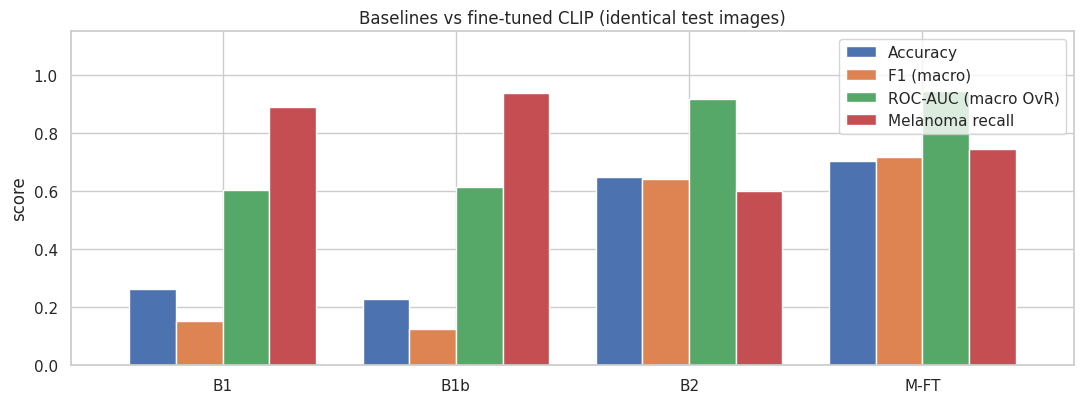

In [12]:
test_logits = eval_logits(imgs_test, tta=True).numpy()
p = softmax_np(test_logits / TEMPERATURE)
results["M-FT Fine-tuned CLIP (ours)"] = {"prob": p, "pred": p.argmax(1)}
test_logits_noTTA = eval_logits(imgs_test, tta=False).numpy()
p0 = softmax_np(test_logits_noTTA / TEMPERATURE)
print(f"Fine-tuned, no TTA: acc {(p0.argmax(1) == y_test).mean():.4f} | with flip-TTA: {(p.argmax(1) == y_test).mean():.4f}")

from sklearn.metrics import (precision_recall_fscore_support, roc_auc_score, confusion_matrix, roc_curve, auc)
from sklearn.preprocessing import label_binarize
def evaluate(y, pred, prob):
    pr, rc, f1, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
    return {"Accuracy": accuracy_score(y, pred), "Precision (macro)": pr, "Recall (macro)": rc, "F1 (macro)": f1,
            "F1 (weighted)": precision_recall_fscore_support(y, pred, average="weighted", zero_division=0)[2],
            "ROC-AUC (macro OvR)": roc_auc_score(y, prob, multi_class="ovr", average="macro", labels=list(range(K))),
            "Melanoma recall": ((pred == MEL) & (y == MEL)).sum() / (y == MEL).sum()}

metrics_df = pd.DataFrame({n: evaluate(y_test, r["pred"], r["prob"]) for n, r in results.items()}).T
metrics_df.to_csv(os.path.join(OUT_DIR, "metrics_comparison.csv"))
print(f"test set: {len(y_test)} images (same as the original project)")
try: display(metrics_df.style.format("{:.4f}").highlight_max(axis=0, color="#b7e4c7"))
except Exception: display(metrics_df.round(4))

ax = metrics_df[["Accuracy", "F1 (macro)", "ROC-AUC (macro OvR)", "Melanoma recall"]].plot(kind="bar", figsize=(11, 4.2), width=0.8)
ax.set_xticklabels([n.split()[0] for n in metrics_df.index], rotation=0); ax.set_ylim(0, 1.15); ax.set_ylabel("score")
ax.set_title("Baselines vs fine-tuned CLIP (identical test images)"); plt.tight_layout(); plt.show()

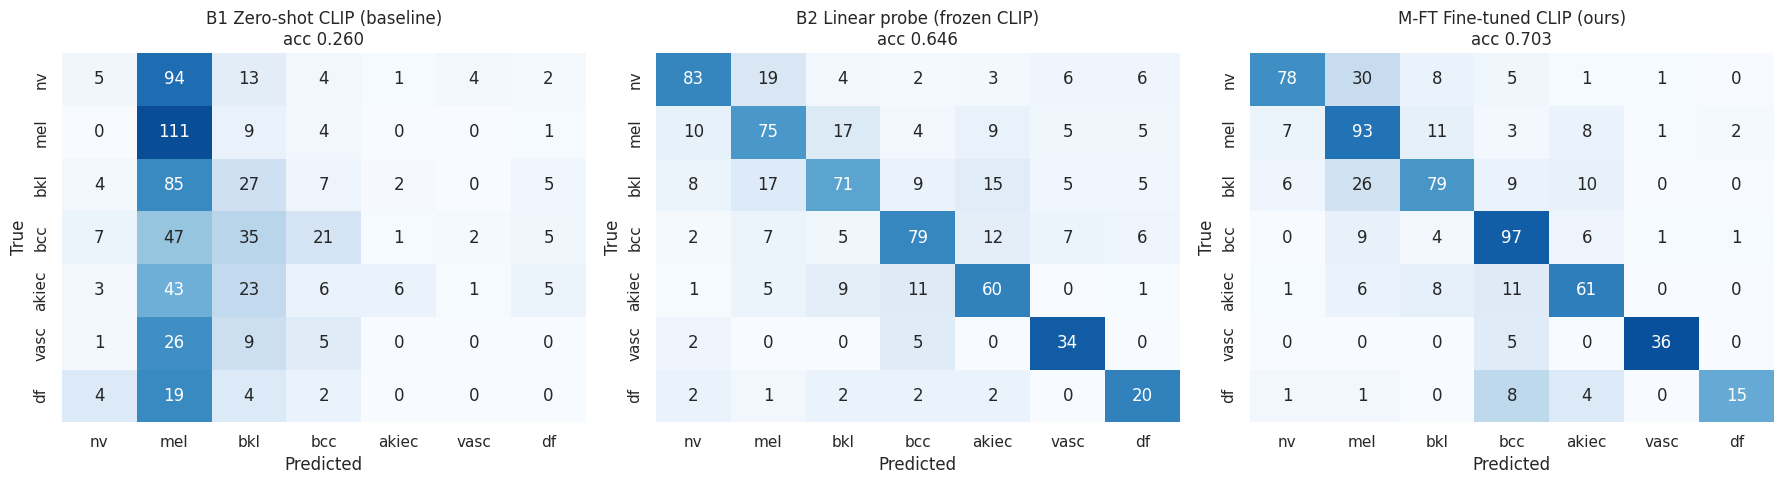

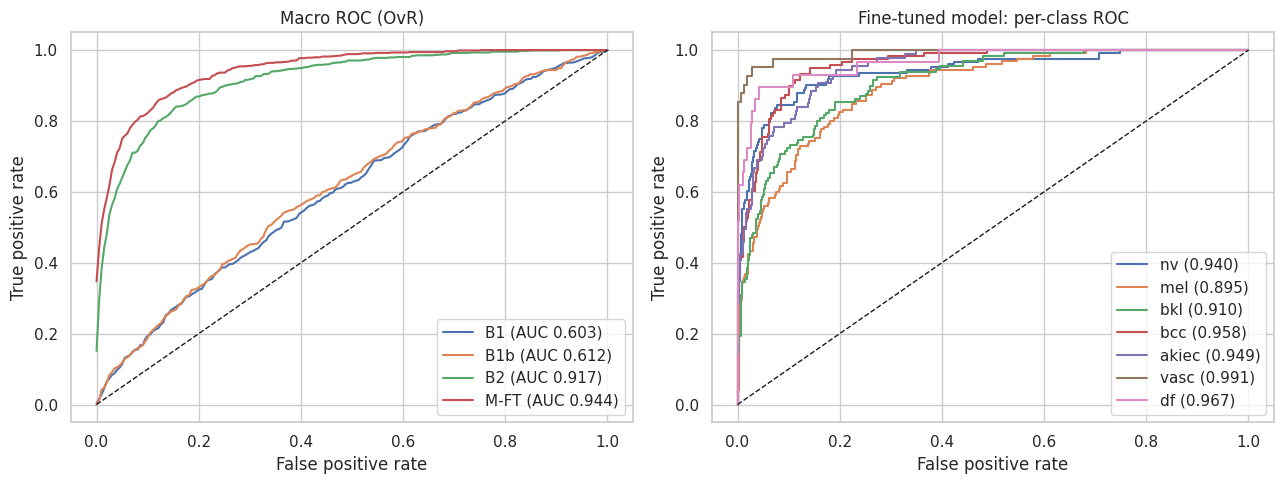

              precision    recall  f1-score   support

          nv      0.839     0.634     0.722       123
         mel      0.564     0.744     0.641       125
         bkl      0.718     0.608     0.658       130
         bcc      0.703     0.822     0.758       118
       akiec      0.678     0.701     0.689        87
        vasc      0.923     0.878     0.900        41
          df      0.833     0.517     0.638        29

    accuracy                          0.703       653
   macro avg      0.751     0.701     0.715       653
weighted avg      0.721     0.703     0.704       653



In [13]:
# Confusion matrices (colour = row-normalised recall, numbers = counts)
show = ["B1 Zero-shot CLIP (baseline)", "B2 Linear probe (frozen CLIP)", "M-FT Fine-tuned CLIP (ours)"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, n_ in zip(axes, show):
    cm = confusion_matrix(y_test, results[n_]["pred"], labels=list(range(K)))
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=cm, fmt="d", cmap="Blues", vmin=0, vmax=1, cbar=False,
                xticklabels=CODES, yticklabels=CODES, ax=ax)
    ax.set_title(f"{n_}\nacc {metrics_df.loc[n_, 'Accuracy']:.3f}"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.show()

# ROC
Yb = label_binarize(y_test, classes=list(range(K))); grid = np.linspace(0, 1, 200)
def macro_roc(prob): return np.mean([np.interp(grid, *roc_curve(Yb[:, k], prob[:, k])[:2]) for k in range(K)], axis=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for n_, r in results.items():
    axes[0].plot(grid, macro_roc(r["prob"]), label=f"{n_.split()[0]} (AUC {metrics_df.loc[n_, 'ROC-AUC (macro OvR)']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_title("Macro ROC (OvR)"); axes[0].legend(loc="lower right")
ft = results["M-FT Fine-tuned CLIP (ours)"]["prob"]
for k in range(K):
    f_, t_, _ = roc_curve(Yb[:, k], ft[:, k]); axes[1].plot(f_, t_, label=f"{CODES[k]} ({auc(f_, t_):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].set_title("Fine-tuned model: per-class ROC"); axes[1].legend(loc="lower right")
for a_ in axes: a_.set_xlabel("False positive rate"); a_.set_ylabel("True positive rate")
plt.tight_layout(); plt.show()

from sklearn.metrics import classification_report
print(classification_report(y_test, results["M-FT Fine-tuned CLIP (ours)"]["pred"], target_names=CODES, digits=3))

### 7.1 Is the improvement real? Paired bootstrap over lesions

In [14]:
def paired_bootstrap(pred_a, pred_b, y, groups, n=2000, seed=SEED):
    rng = np.random.RandomState(seed)
    ug = np.unique(groups); idx_of = {g: np.where(groups == g)[0] for g in ug}
    ca, cb = (pred_a == y).astype(float), (pred_b == y).astype(float); diffs = []
    for _ in range(n):
        ii = np.concatenate([idx_of[g] for g in rng.choice(ug, len(ug), replace=True)])
        diffs.append(cb[ii].mean() - ca[ii].mean())
    return np.mean(diffs), np.percentile(diffs, [2.5, 97.5])

g_test = test_df["lesion_id"].values
ft_pred = results["M-FT Fine-tuned CLIP (ours)"]["pred"]
rows = []
for n_ in [k for k in results if not k.startswith("M-FT")]:
    d, (lo, hi) = paired_bootstrap(results[n_]["pred"], ft_pred, y_test, g_test)
    rows.append({"vs": n_, "acc baseline": (results[n_]["pred"] == y_test).mean(), "acc fine-tuned": (ft_pred == y_test).mean(),
                 "Δ accuracy": d, "95% CI low": lo, "95% CI high": hi, "significant": lo > 0})
sig = pd.DataFrame(rows); display(sig.round(4))
beats_baseline = bool(sig["significant"].all())
print("\nFine-tuned CLIP beats EVERY baseline with a 95%-CI above zero:", beats_baseline)
if not beats_baseline:
    print("⚠️ Not clearly better: try ViT-B/16, N_UNFROZEN=6, more epochs, or TRAIN_CAP_PER_CLASS=3000 before deploying.")

,vs,acc baseline,acc fine-tuned,Δ accuracy,95% CI low,95% CI high,significant
0,B1 Zero-shot CLIP (baseline),0.2603,0.7029,0.4428,0.3893,0.4969,True
1,B1b Zero-shot CLIP (prompt ensemble),0.2282,0.7029,0.4747,0.4237,0.5280,True
2,B2 Linear probe (frozen CLIP),0.6462,0.7029,0.0565,0.0210,0.0935,True



Fine-tuned CLIP beats EVERY baseline with a 95%-CI above zero: True


### 7.2 Examples

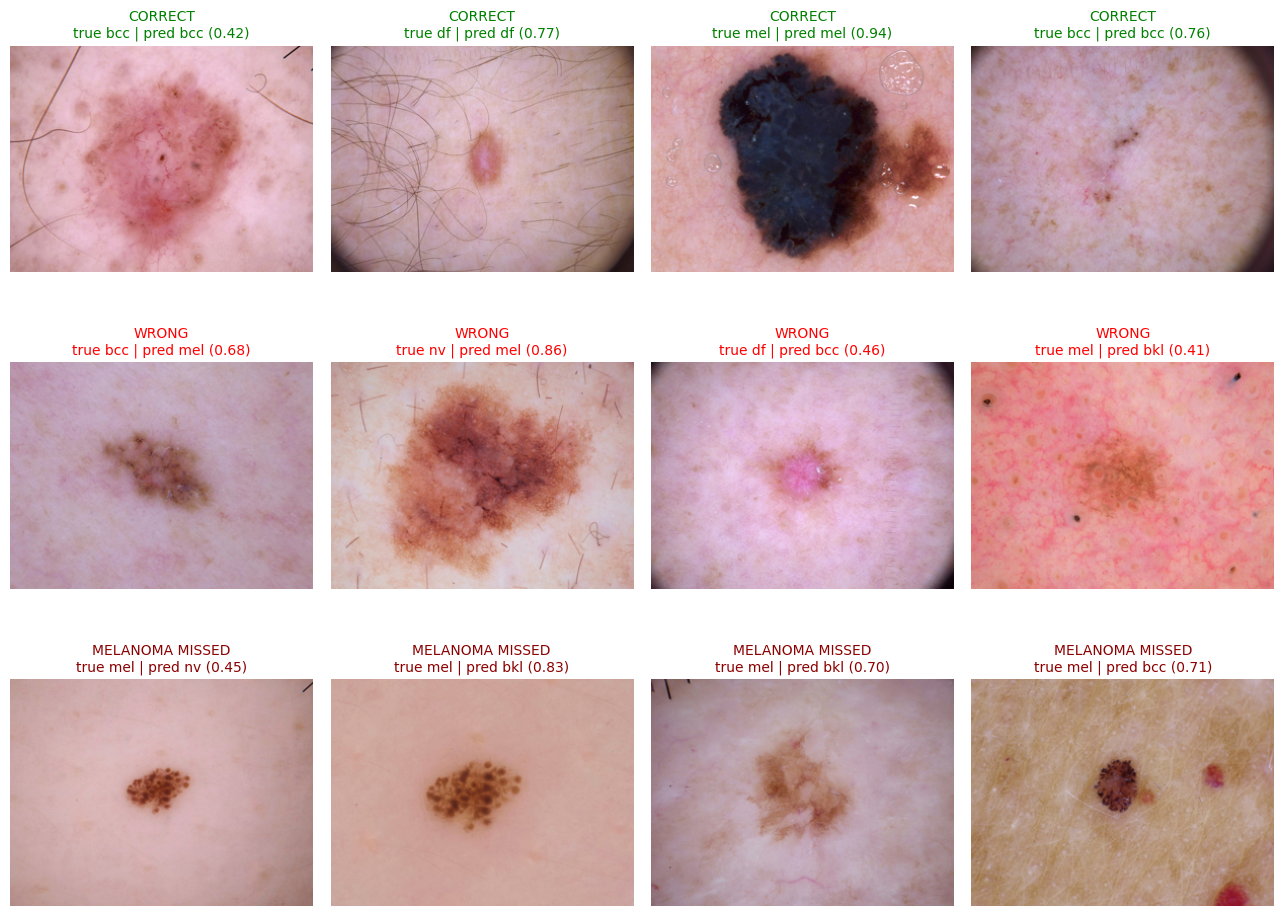

In [15]:
rng = np.random.RandomState(SEED); pred_ft = ft_pred; conf_ft = results["M-FT Fine-tuned CLIP (ours)"]["prob"].max(1)
rows = [("CORRECT", np.where(pred_ft == y_test)[0], "green"), ("WRONG", np.where(pred_ft != y_test)[0], "red"),
        ("MELANOMA MISSED", np.where((y_test == MEL) & (pred_ft != MEL))[0], "darkred")]
fig, axes = plt.subplots(3, 4, figsize=(13, 10))
for r, (lab, idxs, col) in enumerate(rows):
    pick = rng.permutation(idxs)[:4] if len(idxs) else []
    for c in range(4):
        ax = axes[r, c]; ax.axis("off")
        if c < len(pick):
            i = pick[c]; ax.imshow(imgs_test[i])
            ax.set_title(f"{lab}\ntrue {CODES[y_test[i]]} | pred {CODES[pred_ft[i]]} ({conf_ft[i]:.2f})", color=col, fontsize=10)
plt.tight_layout(); plt.show()

## 8 · Export for the web app
Writes into `skin_clip_export/`:
* `clip_skin_ft.pt` – tuned tensors only (fp16), head, temperature (≈ tens of MB)
* `metadata.json` – class list, metrics, `beats_baseline`, version
* `replay/` – small image set + `manifest.csv` used by `retrain.py` to prevent forgetting
* `metrics_comparison.csv`

In [16]:
ckpt = {"visual_tuned": net.tuned_visual_state(N_UNFROZEN), "head_weight": net.head.detach().cpu().float(),
        "logit_scale": float(net.logit_scale.detach().cpu()), "temperature": TEMPERATURE, "backbone": BACKBONE,
        "classes": classes, "codes": CODES, "n_blocks": N_UNFROZEN, "version": MODEL_VERSION}
ckpt_path = os.path.join(OUT_DIR, "clip_skin_ft.pt")
torch.save(ckpt, ckpt_path)
print(f"saved {ckpt_path}  ({os.path.getsize(ckpt_path)/1e6:.1f} MB)")

metadata = {"version": MODEL_VERSION, "backbone": BACKBONE, "classes": classes, "codes": CODES,
            "trained_on": "HAM10000 (lesion-grouped split)", "temperature": TEMPERATURE,
            "beats_baseline": beats_baseline, "metrics": metrics_df.round(4).to_dict(orient="index"),
            "config": dict(N_UNFROZEN=N_UNFROZEN, EPOCHS=EPOCHS, LR_BACKBONE=LR_BACKBONE, LR_HEAD=LR_HEAD,
                           LABEL_SMOOTH=LABEL_SMOOTH, TRAIN_CAP_PER_CLASS=TRAIN_CAP_PER_CLASS, SEED=SEED),
            "n_train": int(len(y_train)), "n_val": int(len(y_val)), "n_test": int(len(y_test))}
json.dump(metadata, open(os.path.join(OUT_DIR, "metadata.json"), "w"), indent=2)

# replay set for the feedback loop (<= 40 train images per class, 224px JPEGs)
rp_dir = os.path.join(OUT_DIR, "replay"); os.makedirs(rp_dir, exist_ok=True); rows = []
for k in range(K):
    for j, i in enumerate(np.where(y_train == k)[0][:40]):
        fn = f"{CODES[k]}_{j:02d}.jpg"; imgs_train[i].save(os.path.join(rp_dir, fn), quality=92); rows.append((fn, CODES[k]))
pd.DataFrame(rows, columns=["file", "label"]).to_csv(os.path.join(rp_dir, "manifest.csv"), index=False)
print("replay images:", len(rows))

saved skin_clip_export/clip_skin_ft.pt  (57.5 MB)
replay images: 280


In [17]:
# ---- sanity: reload the exported file the way the web app does and re-score the test set ----
import clip as _clip
b2, pre2 = _clip.load(BACKBONE, device="cpu", jit=False); b2 = b2.float().eval()
ck = torch.load(ckpt_path, map_location="cpu", weights_only=True)
b2.visual.load_state_dict({k: v.float() for k, v in ck["visual_tuned"].items()}, strict=False)
net2 = SkinCLIPNet(b2.visual, ck["head_weight"], ck["logit_scale"]).to(device).eval()
live = net; net = net2
re_logits = eval_logits(imgs_test, tta=True).numpy(); net = live
re_acc = (re_logits.argmax(1) == y_test).mean()
print(f"in-memory acc {(ft_pred == y_test).mean():.4f} | reloaded-from-file acc {re_acc:.4f}")
assert abs(re_acc - (ft_pred == y_test).mean()) < 0.01, "exported checkpoint does not reproduce the evaluated model"
print("✅ export verified")

# bundle for download
shutil.make_archive("skin_clip_export", "zip", OUT_DIR)
try:
    from google.colab import files; files.download("skin_clip_export.zip")
except Exception:
    print("zip written: skin_clip_export.zip")

in-memory acc 0.7029 | reloaded-from-file acc 0.7014
✅ export verified


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9 · Deploying & the physician feedback loop

1. Copy the contents of `skin_clip_export/` into the web app's `model/` folder (`clip_skin_ft.pt`, `metadata.json`, `replay/`).
2. Run the app (`streamlit run app.py`, or the Dockerfile). Physicians **approve / correct / reject** each prediction; every review is stored in SQLite together with the de-identified image.
3. When enough reviews accumulate (default 200), run `python retrain.py --data-dir data --ckpt model/clip_skin_ft.pt`.
   It fine-tunes from the current checkpoint on *feedback + replay*, compares old vs new on held-out feedback **and** held-out replay images, and only promotes the candidate (`--promote`) if it does not regress.
4. Re-run section 7 of this notebook on a *fixed* gold test set before every promotion if you can: physician feedback is a training signal, not an unbiased test set.

**Limitations to state honestly**
* HAM10000 is dermoscopy from two sites with mostly lighter skin tones; performance on other devices / skin tones / smartphone photos is unknown.
* Test accuracy here is on a class-balanced *sample* of HAM10000 (`MAX_PER_CLASS=500`), which is not the real-world class prevalence.
* The feedback loop inherits reviewer bias and can drift; weight histopathology-confirmed labels highest and monitor agreement over time.